# IFRS 9 / CECL Lifetime PD & ECL with Survival Models

Since the 2008 crisis, banks have to provision for losses they expect, not only for losses that have already happened. For a mortgage book that means estimating, for every loan, the chance of default in every future month until maturity, under several economic scenarios. This notebook builds that machinery on 500,000 real U.S. mortgages: loans originated in 2005–08, which went through the housing crisis, and loans originated in 2018–23, which went through the pandemic.

**What it does.** It builds lifetime default probabilities and expected credit losses from Fannie Mae and Freddie Mac loan-level data.

It compares three survival models for default timing (Cox, random survival forest, DeepSurv) and fits monthly cause-specific hazards for default and prepayment whose sensitivity to house prices and unemployment is estimated on the crisis years themselves. It tests the default model out of time twice: on 2024–26, and on the crisis, with a model trained only on data up to 2008.

Each active loan is projected to maturity under the Federal Reserve's 2026 baseline and severely adverse scenarios, with a loss given default estimated from 13,500 crisis foreclosure and short sales. The notebook then computes IFRS 9 staged ECL (12-month against lifetime, with a test for a significant increase in credit risk) and CECL lifetime ECL.

**Data.** Fannie Mae Single-Family Loan Performance data for 2005–2008 acquisitions and the Freddie Mac Single-Family Loan-Level Dataset for 2018–2023 (50,000 loans per vintage, monthly performance to March 2026); the U.S. unemployment rate, Case-Shiller national and FHFA state house prices and the 30-year mortgage rate (FRED); and the Fed's 2026 supervisory scenarios (federalreserve.gov).

**Methods.** A default definition that excludes COVID forbearance, Cox proportional hazards (lifelines), a random survival forest (scikit-survival) and a DeepSurv network (PyTorch) on origination data.

The projections use discrete-time logistic hazards with competing risks and a mark-to-market LTV rebuilt from state house prices, two back-tests, an empirical downturn LGD, amortising EAD, scenario-weighted lifetime PD and ECL, and stage allocation.

**Key output.** A comparison of survival models, the drivers of default and prepayment, out-of-time and crisis calibration, the LGD fit, lifetime PD by vintage, ECL by stage and scenario, and the difference between CECL and IFRS 9.

## 1. Expected credit loss in one page

Both accounting standards replaced "incurred loss" with **expected** loss after 2008, but they differ in scope:

| | IFRS 9 | CECL (U.S. GAAP, ASC 326) |
|---|---|---|
| Stage 1 (performing, no significant increase in risk) | 12-month ECL | lifetime ECL |
| Stage 2 (significant increase in credit risk, SICR) | lifetime ECL | lifetime ECL |
| Stage 3 (credit-impaired) | lifetime ECL, interest on net amount | lifetime ECL |
| Forward-looking information | multiple scenarios, probability-weighted | reasonable and supportable forecast, then reversion |

For a loan observed at the reporting date with monthly default hazard $h_d(t)$ and prepayment hazard $h_p(t)$, survival is $S(t)=\prod_{u\le t}[1-h_d(u)-h_p(u)]$, and

$$\text{ECL}=\sum_{t=1}^{T} S(t-1)\,h_d(t)\;\text{LGD}\;\text{EAD}(t)\;(1+r/12)^{-t},$$

with $T=12$ months for IFRS 9 stage 1 and the remaining life otherwise. Prepayment matters: it is a **competing risk** that ends exposure before default can happen, so ignoring it overstates lifetime PD.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import duckdb
import lightgbm as lgb
import statsmodels.api as sm
import torch
from lifelines import CoxPHFitter
from sklearn.model_selection import train_test_split
from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 9
# 1 in 8 loans enter the monthly hazard panel (memory)
HAZARD_SAMPLE = 8
# hazard back-test: train on months before 2024, test on 2024-01 → latest
OOT_START = 202401
FED = "https://www.federalreserve.gov/supervisionreg/files/2026_Final_Supervisory_{}_Domestic.csv"
SCENARIOS = {
    "Baseline": 0.60,
    "Adverse (midpoint)": 0.30,
    "Severely adverse": 0.10,
}
# where macro variables revert after the Fed horizon
LONG_RUN = {"unrate": 4.5, "hpi_yoy": 3.0, "mort_rate": 6.0}
# crisis back-test: train on months to Dec 2008, test on 2009-2011
CRISIS_TRAIN_END, CRISIS_TEST = 200812, (200901, 201112)
# stage 2 if 12m PD ≥ 2× its origination value and at least +0.5 pp, or 30+ dpd
SICR_MULT, SICR_ABS = 2.0, 0.005
torch.manual_seed(SEED)

print(
    f"duckdb {duckdb.__version__} · torch {torch.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

duckdb 1.5.6 · torch 2.14.1+cu130 · run on 2026-10-28


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


# --- Freddie Mac Single-Family Loan-Level Dataset (sample files)
# Download manually (free registration, non-commercial licence):
# https://freddiemac.embs.com/FLoan/Data/download.php
# → "Sample Dataset" → sample_YYYY.zip, saved in data/freddie_mac/ at the repo
# root.
# The files are licensed and are never committed: data/ is in .gitignore.
import zipfile


def find_shared_data(name):
    """
    Find data/<name> in this project's folder or any folder above it, up to the
    repo root (works with sub-folders).
    """
    for d in [PROJECT_DIR, *PROJECT_DIR.parents]:
        if (d / "data" / name).exists():
            return d / "data" / name
        if (d / ".git").exists():
            break
    return None


FREDDIE_DIR = find_shared_data("freddie_mac")
if FREDDIE_DIR is None or not list(FREDDIE_DIR.glob("sample_*.zip")):
    raise FileNotFoundError(
        "Put the Freddie Mac sample_YYYY.zip files in FIN/data/freddie_mac/"
        " (see the link above)."
    )
FM_TXT = DATA_DIR / "freddie_txt"
FM_TXT.mkdir(exist_ok=True)
for z in sorted(FREDDIE_DIR.glob("sample_*.zip")):
    with zipfile.ZipFile(z) as f:
        for m in f.namelist():
            if not (FM_TXT / m).exists():
                f.extract(m, FM_TXT)
VINTAGES = sorted(int(p.stem[-4:]) for p in FM_TXT.glob("sample_orig_*.txt"))

ORIG_COLS = [
    "credit_score",
    "first_pay_date",
    "first_time_buyer",
    "maturity_date",
    "msa",
    "mi_pct",
    "n_units",
    "occupancy",
    "cltv",
    "dti",
    "orig_upb",
    "ltv",
    "orig_rate",
    "channel",
    "ppm_flag",
    "amort_type",
    "state",
    "prop_type",
    "zip3",
    "loan_id",
    "purpose",
    "orig_term",
    "n_borrowers",
    "seller_servicer",
    "super_conforming",
    "pre_relief_id",
    "program",
    "relief_refi",
    "valuation_method",
    "io_flag",
    "mi_cancel",
]
PERF_COLS = {
    0: "loan_id",
    1: "period",
    2: "upb",
    3: "dq",
    4: "age",
    5: "months_left",
    7: "mod_flag",
    8: "zb_code",
    9: "zb_date",
    10: "rate",
    21: "actual_loss",
    25: "eltv",
    26: "zb_upb",
    29: "assistance",
}


def freddie_con():
    con = duckdb.connect(
        str(DATA_DIR / "freddie.duckdb")
    )  # tables on disk, not in the notebook's memory
    con.execute("SET enable_progress_bar = false")
    con.execute("SET memory_limit = '2GB'")
    orig_sel = ", ".join(
        f"column{i:02d} AS {c}" for i, c in enumerate(ORIG_COLS)
    )
    con.execute(
        f"""CREATE OR REPLACE VIEW orig AS SELECT {orig_sel}
                    FROM read_csv('{(FM_TXT / "sample_orig_*.txt").as_posix()}', delim='|', header=false, all_varchar=true)"""
    )
    perf_sel = ", ".join(f"column{i:02d} AS {c}" for i, c in PERF_COLS.items())
    con.execute(
        f"""CREATE OR REPLACE VIEW perf AS SELECT {perf_sel}
                    FROM read_csv('{(FM_TXT / "sample_perf_*.txt").as_posix()}', delim='|', header=false, all_varchar=true)"""
    )
    return con


# --- Fannie Mae Single-Family Loan Performance data, 2005-2008 acquisitions
# Download manually (free registration): https://capitalmarkets.fanniemae.com
# → Single-Family Loan Performance Data → quarterly files 2005Q1 ... 2008Q4,
# saved as data/fannie_mae/2005Q1.zip ... at the repo root. The first run
# builds a sample in the Freddie Mac sample format (12,500 loans per quarter,
# 50,000 per vintage, monthly history) in data/fannie_mae/sample/ and reuses
# it afterwards. The files are licensed and are never committed.
import random


def _ym(s):
    return s[2:] + s[:2] if len(s) == 6 else ""


def _num(s, d=0.0):
    try:
        return float(s)
    except ValueError:
        return d


def fannie_quarter_to_sample(zip_path, yy, q, out_dir, keep=12_500,
                             share=0.08):
    """Filter one quarterly file (loan id mod 1000 < 80), draw `keep` loans
    and append them to sample_orig_20yy.txt / sample_perf_20yy.txt."""
    with zipfile.ZipFile(zip_path) as zf:
        name = zf.namelist()[0]
        lines = []
        with zf.open(name) as f:
            for raw in f:
                line = raw.decode("latin-1")
                lid = line.split("|", 3)[1]
                if int(lid) % 1000 < share * 1000:
                    lines.append(line)
    ids, seen = [], set()
    for line in lines:
        i = line.split("|", 3)[1]
        if i not in seen:
            seen.add(i)
            ids.append(i)
    random.seed(int(f"20{yy}{q}"))
    chosen = set(random.sample(ids, min(keep, len(ids))))
    new_id = {i: f"F{yy}Q{q}{k:07d}" for k, i in enumerate(sorted(chosen))}
    fo = open(out_dir / f"sample_orig_20{yy}.txt", "a")
    fp = open(out_dir / f"sample_perf_20{yy}.txt", "a")
    done, last_age = set(), {}
    for line in lines:
        x = line.rstrip("\n").split("|")
        lid = x[1]
        if lid not in chosen:
            continue
        p = lambda k: x[k - 1] if k - 1 < len(x) else ""
        nid = new_id[lid]
        if lid not in done:
            done.add(lid)
            purpose = {"P": "P", "C": "C", "R": "N"}.get(p(27), "9")
            o = [p(24) or "9999", _ym(p(15)),
                 p(26) if p(26) in ("Y", "N") else "9", _ym(p(19)), p(32),
                 p(34) or "0", p(29), p(30), p(21) or "999", p(23) or "999",
                 str(int(_num(p(10)))), p(20) or "999", p(8), p(4) or "9",
                 p(36) or "N", p(35) or "FRM", p(31), p(28), p(33), nid,
                 purpose, p(13), p(22) or "99", (p(5) or "OTHER").upper(),
                 p(87) or "N", "", p(79), p(103) or "N", p(86) or "9",
                 p(37) or "N", p(43) or "9999"]
            fo.write("|".join(o) + "\n")
        per, zb, upb = _ym(p(3)), p(44), _num(p(12))
        age = int(_num(p(16), -1))
        if age < 0:
            age = last_age.get(lid, -1) + 1
        last_age[lid] = age
        if upb == 0 and not zb:         # masked in the first months
            upb = _num(p(11)) or _num(p(10))
        loss = ""
        if p(59) or p(60) or p(62):     # disposition: Freddie-style loss
            zbu, rate = _num(p(46)), _num(p(9)) or _num(p(8))
            lp, zd = _ym(p(51)), _ym(p(45)) or per
            gap = ((int(zd[:4]) - int(lp[:4])) * 12 + int(zd[4:])
                   - int(lp[4:])) if lp and zd else 0
            dai = zbu * rate / 1200 * max(gap - 1, 0)
            costs = sum(_num(p(k)) for k in (54, 55, 56, 57, 58))
            proceeds = sum(_num(p(k)) for k in (59, 60, 61, 62))
            loss = f"{proceeds - zbu - costs - dai:.2f}"
        r = [""] * 35
        r[0], r[1], r[2] = nid, per, f"{0.0 if zb else upb:.2f}"
        r[3] = "" if p(40) == "XX" else p(40)
        r[4], r[5] = str(age), p(18)
        r[7] = "Y" if p(42) == "Y" else ""
        r[8], r[9], r[10] = zb, _ym(p(45)), p(9) or p(8)
        r[11], r[12] = p(63) or "0.00", _ym(p(51))
        r[21], r[26], r[29] = loss, (p(46) if zb else ""), p(102)
        r[31] = f"{_num(p(110)) or (0.0 if zb else upb):.2f}"
        r[33] = (p(6) or "OTHER").upper()
        fp.write("|".join(r) + "\n")
    fo.close()
    fp.close()


def fannie_sample_zips():
    src = find_shared_data("fannie_mae")
    if src is None:
        return []
    out = src / "sample"
    if not list(out.glob("sample_*.zip")):
        quarters = sorted(src.glob("20??Q?.zip"))
        if not quarters:
            return []
        out.mkdir(exist_ok=True)
        tmp = DATA_DIR / "fannie_build"
        tmp.mkdir(exist_ok=True)
        for z in quarters:              # about 1-2 minutes per quarter
            print("sampling", z.name)
            fannie_quarter_to_sample(z, z.stem[2:4], z.stem[-1], tmp)
        for y in sorted({z.stem[:4] for z in quarters}):
            with zipfile.ZipFile(out / f"sample_{y}.zip", "w",
                                 zipfile.ZIP_DEFLATED) as zf:
                for kind in ["orig", "perf"]:
                    zf.write(tmp / f"sample_{kind}_{y}.txt",
                             f"sample_{kind}_{y}.txt")
    return sorted(out.glob("sample_*.zip"))


for z in fannie_sample_zips():
    with zipfile.ZipFile(z) as f:
        for m in f.namelist():
            if not (FM_TXT / m).exists():
                f.extract(m, FM_TXT)
VINTAGES = sorted(int(p.stem[-4:]) for p in FM_TXT.glob("sample_orig_*.txt"))


## 3. Data: loans, events and the default definition

Two samples in the same format: 200,000 Fannie Mae loans originated in 2005–2008 (12,500 drawn at random from each quarter's acquisitions) and 300,000 Freddie Mac loans originated in 2018–2023, all followed month by month to March 2026.

**Default** is the first month a loan is 90 or more days delinquent while *not* in a COVID-era forbearance plan, or the month it ends in a credit event (third-party sale, short sale, REO or note sale). Forbearance delinquencies are excluded because they were payment deferrals agreed with the servicer, not defaults; most U.S. lenders and regulators treated them that way.

**Prepayment** is a voluntary payoff (zero-balance code 01). Loans that are still active in March 2026 are censored. **Severity** is the realised loss on a credit event (unpaid balance, unpaid interest and liquidation costs, net of sale and mortgage-insurance proceeds) over the balance at default.

In [3]:
con = freddie_con()
con.execute("""
CREATE OR REPLACE TABLE p AS
SELECT loan_id, CAST(period AS INT) AS per, CAST(age AS INT) AS age, TRY_CAST(upb AS DOUBLE) AS upb, dq, zb_code,
       COALESCE(assistance, '') AS assistance, TRY_CAST(actual_loss AS DOUBLE) AS loss, TRY_CAST(zb_upb AS DOUBLE) AS zb_upb,
       TRY_CAST(months_left AS INT) AS months_left, TRY_CAST(rate AS DOUBLE) AS rate, TRY_CAST(eltv AS DOUBLE) AS eltv
FROM perf""")
con.execute("""
CREATE OR REPLACE TABLE ev AS
WITH d AS (SELECT loan_id, MIN(age) AS d_age, MIN(per) AS d_per FROM p
           WHERE (dq NOT IN ('00', '01', '02', 'RA') AND assistance <> 'F') OR zb_code IN ('02', '03', '09', '15') GROUP BY 1),
     z AS (SELECT loan_id, MIN(CASE WHEN zb_code = '01' THEN age END) AS pp_age, MAX(age) AS last_age, MAX(per) AS last_per,
                  arg_max(dq, per) AS last_dq, arg_max(assistance, per) AS last_assist, arg_max(upb, per) AS last_upb,
                  arg_max(zb_code, per) AS last_zb, arg_max(months_left, per) AS last_months_left, arg_max(rate, per) AS last_rate,
                  arg_max(eltv, per) AS last_eltv
           FROM p GROUP BY 1),
     sev AS (SELECT loan_id, -loss / NULLIF(zb_upb, 0) AS severity, zb_upb AS default_upb, per AS sev_per
             FROM p WHERE zb_code IN ('02', '03', '09', '15') AND loss IS NOT NULL)
SELECT o.*, z.*, d.d_age, d.d_per, sev.severity, sev.default_upb, sev.sev_per
FROM orig o JOIN z USING (loan_id) LEFT JOIN d USING (loan_id) LEFT JOIN sev USING (loan_id)
ORDER BY loan_id""")
ev = con.execute("SELECT * FROM ev").df()
for c in [
    "credit_score",
    "cltv",
    "dti",
    "orig_upb",
    "orig_rate",
    "orig_term",
    "n_borrowers",
    "mi_pct",
]:
    ev[c] = pd.to_numeric(ev[c], errors="coerce")
# 9999 = not available
ev.loc[ev["credit_score"] > 850, "credit_score"] = np.nan
ev.loc[ev["cltv"] > 200, "cltv"] = np.nan
ev.loc[ev["dti"] > 65, "dti"] = np.nan
ev["vintage"] = 2000 + ev["loan_id"].str[1:3].astype(int)
ev["era"] = np.where(ev["vintage"] <= 2008, "2005–08 (Fannie Mae)",
                     "2018–23 (Freddie Mac)")
ev["ltv"] = pd.to_numeric(ev["ltv"], errors="coerce").where(
    lambda s: s.between(1, 200))
ev["event"] = np.select(
    [
        ev["d_age"].notna()
        & (ev["pp_age"].isna() | (ev["d_age"] <= ev["pp_age"])),
        ev["pp_age"].notna(),
    ],
    ["default", "prepaid"],
    "active",
)
ev["T"] = (
    np.select(
        [ev["event"] == "default", ev["event"] == "prepaid"],
        [ev["d_age"], ev["pp_age"]],
        ev["last_age"],
    ).astype(float)
    + 1
)
ev["cash_out"] = (ev["purpose"] == "C").astype(int)
ev["investor"] = (ev["occupancy"] == "I").astype(int)
ev["single_borrower"] = (ev["n_borrowers"] == 1).astype(int)
ev["first_time"] = (ev["first_time_buyer"] == "Y").astype(int)
ev["term_15"] = (ev["orig_term"] <= 180).astype(int)
ev["log_upb"] = np.log(ev["orig_upb"])
sev = ev["severity"].dropna()
print(ev.groupby("era").agg(loans=("loan_id", "size"),
                            defaults=("event", lambda s: (s == "default").mean()),
                            median_severity=("severity", "median"))
      .to_string(formatters={"defaults": "{:.1%}".format,
                             "median_severity": "{:.1%}".format}))
print(
    f"{len(ev):,} loans · vintages {VINTAGES[0]}–{VINTAGES[-1]} · performance"
    f" to {ev['last_per'].max()} · {len(sev)} credit-event disposals: median"
    f" realised severity {sev.median():.1%}, {(sev < 0).mean():.0%} sold for"
    " more than the balance"
)
ev.groupby("vintage")["event"].value_counts(normalize=True).unstack().mul(
    100
).round(2)

                        loans defaults median_severity
era                                                   
2005–08 (Fannie Mae)   200000    13.5%           44.3%
2018–23 (Freddie Mac)  300000     2.3%           -9.8%
500,000 loans · vintages 2005–2023 · performance to 202603 · 13890 credit-event disposals: median realised severity 43.6%, 11% sold for more than the balance


event,active,default,prepaid
vintage,,,
2005,2.18,11.31,86.51
2006,1.56,14.51,83.93
2007,1.82,17.03,81.15
2008,1.68,11.25,87.07
2018,18.48,2.82,78.69
2019,27.10,2.65,70.25
2020,60.20,1.38,38.42
2021,79.37,1.68,18.95
2022,77.96,3.07,18.97


## 4. Default timing from origination data: Cox vs random survival forest vs DeepSurv

The three models use the same origination characteristics (credit score, combined LTV, DTI, rate, size, purpose, occupancy, borrowers, first-time buyer, 15-year term, vintage) and treat prepayment as censoring, so they model the **cause-specific** default hazard. They are fitted on 70% of loans and compared on the other 30% with Harrell's C-index.

DeepSurv (Katzman et al., 2018) is a Cox model whose linear predictor is replaced by a neural network trained on the negative partial likelihood.

In [4]:
SURV_X = [
    "credit_score",
    "cltv",
    "dti",
    "orig_rate",
    "log_upb",
    "cash_out",
    "investor",
    "single_borrower",
    "first_time",
    "term_15",
    "vintage",
]
sv = ev.dropna(subset=["credit_score", "cltv", "dti"]).copy()
sv["E"] = (sv["event"] == "default").astype(int)
tr, te = train_test_split(
    sv, test_size=0.3, stratify=sv["E"], random_state=SEED
)
mu, sd = tr[SURV_X].mean(), tr[SURV_X].std()
Ztr, Zte = (tr[SURV_X] - mu) / sd, (te[SURV_X] - mu) / sd

cph = CoxPHFitter(penalizer=0.01).fit(
    Ztr.assign(T=tr["T"], E=tr["E"]), "T", "E"
)
r_cox = cph.predict_partial_hazard(Zte).to_numpy()

# RSF is O(n log n) per tree: a 30k subsample
rs_idx = tr.sample(30_000, random_state=SEED).index
rsf = RandomSurvivalForest(
    n_estimators=200,
    min_samples_leaf=50,
    max_features="sqrt",
    n_jobs=-1,
    random_state=SEED,
)
rsf.fit(
    Ztr.loc[rs_idx],
    Surv.from_arrays(tr.loc[rs_idx, "E"].astype(bool), tr.loc[rs_idx, "T"]),
)
r_rsf = rsf.predict(Zte)


class DeepSurv(torch.nn.Module):
    def __init__(self, k):
        super().__init__()
        self.net = torch.nn.Sequential(
            torch.nn.Linear(k, 32),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.1),
            torch.nn.Linear(32, 16),
            torch.nn.ReLU(),
            torch.nn.Linear(16, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)


def cox_loss(risk, T, E):
    # risk sets: everyone with T_j >= T_i
    order = torch.argsort(T, descending=True)
    risk, E = risk[order], E[order]
    log_cum = torch.logcumsumexp(risk, dim=0)
    return -((risk - log_cum) * E).sum() / E.sum().clamp(min=1)


Xt = torch.tensor(Ztr.to_numpy(), dtype=torch.float32)
Tt, Et = torch.tensor(tr["T"].to_numpy(), dtype=torch.float32), torch.tensor(
    tr["E"].to_numpy(), dtype=torch.float32
)
ds = DeepSurv(len(SURV_X))
opt = torch.optim.Adam(ds.parameters(), lr=1e-3, weight_decay=1e-4)
for epoch in range(30):
    perm = torch.randperm(len(Xt))
    for b in range(0, len(Xt), 8_192):
        i = perm[b : b + 8_192]
        opt.zero_grad()
        loss = cox_loss(ds(Xt[i]), Tt[i], Et[i])
        loss.backward()
        opt.step()
ds.eval()
with torch.no_grad():
    r_ds = ds(torch.tensor(Zte.to_numpy(), dtype=torch.float32)).numpy()

E_te, T_te = te["E"].astype(bool).to_numpy(), te["T"].to_numpy()
surv_cmp = pd.DataFrame({
    "C-index (test)": {
        m: concordance_index_censored(E_te, T_te, r)[0]
        for m, r in [
            ("Cox PH", r_cox),
            ("Random survival forest", r_rsf),
            ("DeepSurv", r_ds),
        ]
    }
})
surv_cmp["training loans"] = [len(tr), len(rs_idx), len(tr)]
hr = pd.DataFrame(
    {"hazard ratio per s.d.": np.exp(cph.params_), "p-value": cph.summary["p"]}
).sort_values("hazard ratio per s.d.")
print(f"Survival sample: {len(sv):,} loans, {sv['E'].sum():,} defaults")
# free memory before the loan-month panel
del rsf, Xt, Tt, Et, Ztr, Zte, tr, te, sv
import gc

gc.collect()
display(surv_cmp.round(4))
hr.round(3)

Survival sample: 492,093 loans, 32,831 defaults


,C-index (test),training loans
Cox PH,0.81,344465
Random survival forest,0.80,30000
DeepSurv,0.82,344465


,hazard ratio per s.d.,p-value
covariate,,
credit_score,0.61,0.00
vintage,0.78,0.00
term_15,0.87,0.00
first_time,0.95,0.00
investor,1.00,0.57
cash_out,1.16,0.00
log_upb,1.20,0.00
single_borrower,1.22,0.00
dti,1.23,0.00


## 5. Monthly hazards: behaviour, competing risks and the economy

Lifetime ECL needs hazards that move with the borrower and with the economy. The projection model is a **discrete-time hazard**: one logistic regression for the monthly probability of default and one for prepayment, on a loan-month panel (a random eighth of the loans, every month until their first event).

Months before January 2024 train the models; January 2024 to the last month test them out of time. The default model leaves out March 2020 – December 2021: in the CARES Act forbearance era a missed payment usually led to a forbearance plan rather than default, which would teach the model that delinquency does not matter. The prepayment model keeps those months, which contain the refinancing wave it has to learn from.

- **Default hazard:** loan age (piecewise linear), origination characteristics, the **mark-to-market LTV** of the previous month, last month's delinquency (30 or 60 days), and **unemployment and house-price growth six months earlier**. Freddie Mac publishes an estimated LTV for each loan-month; for the Fannie Mae loans it is rebuilt from the original LTV, the amortised balance and the FHFA house-price index of the property's state.
- **Prepayment hazard:** the same characteristics plus the **refinancing incentive** (note rate minus the current 30-year mortgage rate), unemployment and house-price growth.

**Macro sensitivity from the loans themselves.** Without the crisis, the 2018–2026 data contain no recession that forbearance did not absorb, and the sensitivity to the economy would have to be borrowed from an aggregate series. With the 2005–08 vintages it is estimated directly. For comparison the notebook still fits the aggregate "satellite": the log-odds of the U.S. bank delinquency rate on single-family mortgages (FRED, 1991 onwards) on unemployment and house-price growth two quarters earlier.

In [5]:
def fetch_macro():
    m = (
        pd.DataFrame({
            "unrate": fred.get_series(
                "UNRATE", observation_start="1990-01-01"
            ),
            "hpi": fred.get_series(
                "CSUSHPINSA", observation_start="1990-01-01"
            ),
        })
        .resample("MS")
        .mean()
    )
    m["mort_rate"] = (
        fred.get_series("MORTGAGE30US", observation_start="1990-01-01")
        .resample("MS")
        .mean()
    )
    return m.rename_axis("date").reset_index()


macro = (
    cached("fred_macro_monthly_1990", fetch_macro, max_age_hours=24 * 7)
    .set_index("date")
    .ffill()
)
macro["unrate_chg12"] = macro["unrate"].diff(12)
macro["hpi_yoy"] = macro["hpi"].pct_change(12, fill_method=None) * 100
macro["per"] = macro.index.year * 100 + macro.index.month


# State house-price indices: the mark-to-market LTV of loans without one
STATES = sorted(ev["state"].dropna().unique())


def fetch_state_hpi():
    out = {}
    for st in STATES:
        try:
            out[st] = fred.get_series(f"{st}STHPI")
        except Exception:
            pass
    return pd.DataFrame(out)


shpi = cached("fred_state_hpi", fetch_state_hpi, max_age_hours=24 * 30)
shpi.index = pd.to_datetime(shpi.index)
shpi = shpi.resample("MS").mean().interpolate().ffill()
shpi_per = shpi.set_axis(shpi.index.year * 100 + shpi.index.month)


def hpi_at(states, pers):
    """State house-price index at YYYYMM periods (last value if later)."""
    pers = np.minimum(np.asarray(pers, dtype=float), shpi_per.index.max())
    idx = np.searchsorted(shpi_per.index.to_numpy(), np.nan_to_num(pers))
    idx = np.clip(idx, 0, len(shpi_per) - 1)
    cols = shpi_per.columns.get_indexer(pd.Series(states).fillna(""))
    vals = shpi_per.to_numpy()[idx, np.maximum(cols, 0)]
    return np.where((cols >= 0) & np.isfinite(pers), vals, np.nan)

# Satellite: bank delinquency rate on single-family mortgages vs macro two
# quarters earlier
dr = fred.get_series("DRSFRMACBS").dropna()
qm = macro[["unrate", "hpi_yoy"]].resample("QS").mean()
sat = pd.DataFrame(
    {"dr": dr, "u_lag": qm["unrate"].shift(2), "g_lag": qm["hpi_yoy"].shift(2)}
).dropna()
sat["logit_dr"] = np.log(sat["dr"] / 100 / (1 - sat["dr"] / 100))
sat_fit = sm.OLS(
    sat["logit_dr"], sm.add_constant(sat[["u_lag", "g_lag"]])
).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
GAMMA_U, GAMMA_G = sat_fit.params["u_lag"], sat_fit.params["g_lag"]
print(
    f"Satellite ({sat.index.min():%Y}–{sat.index.max():%Y},"
    f" {len(sat)} quarters): γ_u = {GAMMA_U:+.3f} per pp unemployment (t ="
    f" {sat_fit.tvalues['u_lag']:.1f}), γ_g = {GAMMA_G:+.3f} per pp"
    f" house-price growth (t = {sat_fit.tvalues['g_lag']:.1f}), R²"
    f" {sat_fit.rsquared:.2f}"
)

con.register(
    "macro",
    macro.reset_index()[
        ["per", "unrate", "unrate_chg12", "hpi_yoy", "mort_rate"]
    ],
)
con.register("ev_x", ev[["loan_id", "event", "T"]])
panel = con.execute(f"""
    WITH q AS (SELECT loan_id, per, age, LAG(eltv) OVER (PARTITION BY loan_id ORDER BY per) AS eltv, dq,
                      LAG(upb) OVER (PARTITION BY loan_id ORDER BY per) AS upb_prev,
                      LAG(dq) OVER (PARTITION BY loan_id ORDER BY per) AS dq_prev
               FROM p WHERE hash(loan_id) % {HAZARD_SAMPLE} = 0)
    SELECT q.loan_id, q.per, q.age, q.eltv, q.upb_prev, q.dq_prev, (e.event = 'default' AND q.age + 1 = e.T)::INT AS y_def,
           (e.event = 'prepaid' AND q.age + 1 = e.T)::INT AS y_pp, m.unrate, m.unrate_chg12, m.hpi_yoy, m.mort_rate,
           m6.unrate AS u_lag6, m6.hpi_yoy AS g_lag6
    FROM q JOIN ev_x e USING (loan_id) LEFT JOIN macro m ON m.per = q.per
    LEFT JOIN macro m6 ON m6.per = CAST(strftime(strptime(CAST(q.per AS VARCHAR), '%Y%m') - INTERVAL 6 MONTH, '%Y%m') AS INT)
    WHERE q.age + 1 <= e.T
    ORDER BY q.loan_id, q.per""").df()
panel = panel.merge(
    ev[["loan_id", "state", "first_pay_date", "orig_upb", "ltv"] + SURV_X]
    .drop_duplicates("loan_id"), on="loan_id"
)
# Fannie Mae does not publish an estimated LTV: rebuild it from the original
# LTV, the amortised balance and the state house-price index
orig_per = pd.to_numeric(panel["first_pay_date"], errors="coerce") - 1
prev_per = (pd.to_datetime(panel["per"].astype(str), format="%Y%m")
            - pd.DateOffset(months=1))
prev_per = prev_per.dt.year * 100 + prev_per.dt.month
eltv_hpi = (panel["ltv"].fillna(panel["cltv"])
            * panel["upb_prev"].fillna(panel["orig_upb"]) / panel["orig_upb"]
            * hpi_at(panel["state"], orig_per) / hpi_at(panel["state"],
                                                         prev_per))
panel["eltv"] = panel["eltv"].where(panel["eltv"].between(1, 300), eltv_hpi)
panel["note_rate"] = panel["orig_rate"]
panel["incentive"] = panel["note_rate"] - panel["mort_rate"]
for c in ["credit_score", "cltv", "dti"]:
    panel[c] = panel[c].fillna(ev[c].median())
panel["eltv"] = (
    panel["eltv"].where(panel["eltv"].between(1, 300)).fillna(panel["cltv"])
)
panel["dq_prev"] = pd.to_numeric(panel["dq_prev"], errors="coerce").fillna(0)
print(
    f"Hazard panel: {len(panel):,} loan-months from"
    f" {panel['loan_id'].nunique():,} loans ·"
    f" {panel['y_def'].sum():,} defaults, {panel['y_pp'].sum():,} prepayments"
)


def default_design(df):
    a = df["age"].clip(0, 120)
    X = pd.DataFrame(
        {
            "const": 1.0,
            "age_0_12": np.minimum(a, 12),
            "age_12_36": np.clip(a - 12, 0, 24),
            "age_36p": np.clip(a - 36, 0, 84),
            "fico_std": (df["credit_score"] - 750) / 50,
            "mtm_ltv_std": (df["eltv"] - 60) / 15,
            "dti_std": (df["dti"] - 36) / 9,
            "log_upb": df["log_upb"] - 12.4,
            "cash_out": df["cash_out"],
            "investor": df["investor"],
            "single_borrower": df["single_borrower"],
            "first_time": df["first_time"],
            "term_15": df["term_15"],
            "unemp_lag6": df["u_lag6"] - 5.0,
            "hpi_growth_lag6": df["g_lag6"] / 10,
            "dq30_prev": (df["dq_prev"] == 1).astype(float),
            "dq60_prev": (df["dq_prev"] >= 2).astype(float),
        },
        index=df.index,
    )
    return X


def prepay_design(df):
    X = default_design(df).drop(columns=["dq30_prev", "dq60_prev"])
    X["incentive"] = df["incentive"]
    X["incentive_pos"] = df["incentive"].clip(lower=0)
    X["unrate"] = df["unrate"] - 4.5
    X["hpi_yoy"] = df["hpi_yoy"] / 10
    return X


class Logit:
    """
    Unpenalised logistic regression by L-BFGS with Wald z-statistics (memory-
    light on millions of rows).
    """

    def __init__(self, X, y):
        from sklearn.linear_model import LogisticRegression

        lr = LogisticRegression(
            penalty=None,
            solver="lbfgs",
            max_iter=3_000,
            tol=1e-8,
            fit_intercept=False,
        ).fit(X, y)
        self.params = lr.coef_.ravel()
        p_ = self.predict(X)
        info = X.T @ (X * (p_ * (1 - p_))[:, None])
        self.tvalues = self.params / np.sqrt(np.diag(np.linalg.inv(info)))

    def predict(self, X):
        from scipy.special import expit

        return expit(X @ self.params)


panel = panel.dropna(
    subset=["unrate", "hpi_yoy", "mort_rate", "u_lag6", "g_lag6"]
).reset_index(drop=True)
# CARES Act era: delinquency did not lead to default
FORBEARANCE = panel["per"].between(202003, 202112)
is_tr = ((panel["per"] < OOT_START) & ~FORBEARANCE).to_numpy()
is_oot = (panel["per"] >= OOT_START).to_numpy()
U_REF, G_REF = (
    panel.loc[is_tr, "u_lag6"].mean(),
    panel.loc[is_tr, "g_lag6"].mean(),
)
Xd, Xq = default_design(panel), prepay_design(panel)
DCOLS, PCOLS = list(Xd.columns), list(Xq.columns)
Xd, Xq = Xd.to_numpy(np.float64), Xq.to_numpy(np.float64)
gc.collect()
m_def = Logit(Xd[is_tr], panel.loc[is_tr, "y_def"].to_numpy())
# prepayment keeps the 2020–21 refinancing wave
is_tr_pp = (panel["per"] < OOT_START).to_numpy()
m_pp = Logit(Xq[is_tr_pp], panel.loc[is_tr_pp, "y_pp"].to_numpy())
B_U = m_def.params[DCOLS.index("unemp_lag6")]
B_G = m_def.params[DCOLS.index("hpi_growth_lag6")] / 10
# default multiplier of a macro path relative to the training average
overlay = lambda u_lag, g_lag: np.exp(
    B_U * (np.asarray(u_lag) - U_REF) + B_G * (np.asarray(g_lag) - G_REF)
)
print(
    f"Loan-level macro sensitivity of the default hazard: {B_U:+.3f} per pp"
    f" unemployment, {B_G:+.3f} per pp house-price growth (satellite on bank"
    f" delinquencies: {GAMMA_U:+.3f} and {GAMMA_G:+.3f})"
)
coefs = pd.concat([
    pd.DataFrame({"β": m_def.params, "z": m_def.tvalues}, index=DCOLS).assign(
        model="default"
    ),
    pd.DataFrame({"β": m_pp.params, "z": m_pp.tvalues}, index=PCOLS).assign(
        model="prepayment"
    ),
])
print(
    f"Reference macro of the training months: unemployment {U_REF:.2f}%,"
    f" house-price growth {G_REF:.1f}%"
)
coefs.round(3)

Satellite (1991–2026, 140 quarters): γ_u = +0.188 per pp unemployment (t = 3.2), γ_g = -0.036 per pp house-price growth (t = -2.8), R² 0.54


Hazard panel: 2,992,985 loan-months from 62,866 loans · 4,361 defaults, 38,148 prepayments


Loan-level macro sensitivity of the default hazard: +0.024 per pp unemployment, -0.038 per pp house-price growth (satellite on bank delinquencies: +0.188 and -0.036)
Reference macro of the training months: unemployment 5.78%, house-price growth 2.3%


,β,z,model
const,-10.32,-53.48,default
age_0_12,0.00,0.01,default
age_12_36,-0.01,-2.23,default
age_36p,0.00,3.43,default
fico_std,0.10,4.72,default
mtm_ltv_std,0.24,12.88,default
dti_std,0.01,0.30,default
log_upb,0.11,2.62,default
cash_out,0.07,1.50,default
investor,0.34,3.77,default


### Out-of-time back-test (January 2024 onwards)

In [6]:
oot = panel[is_oot].copy()
oot["p_def"] = m_def.predict(Xd[is_oot])
oot["p_pp"] = m_pp.predict(Xq[is_oot])
q = oot.groupby(oot["per"] // 100 * 10 + ((oot["per"] % 100 - 1) // 3 + 1))
bt = pd.DataFrame({
    "loan-months": q.size(),
    "actual defaults": q["y_def"].sum(),
    "predicted defaults": q["p_def"].sum(),
    "actual prepayments": q["y_pp"].sum(),
    "predicted prepayments": q["p_pp"].sum(),
})
bt.index = [f"{i // 10} Q{i % 10}" for i in bt.index]
from sklearn.metrics import roc_auc_score

print(
    "Out-of-time AUC: default"
    f" {roc_auc_score(oot['y_def'], oot['p_def']):.3f}, prepayment"
    f" {roc_auc_score(oot['y_pp'], oot['p_pp']):.3f} · defaults predicted"
    f" {oot['p_def'].sum():,.0f} vs actual {oot['y_def'].sum():,} ·"
    f" prepayments {oot['p_pp'].sum():,.0f} vs {oot['y_pp'].sum():,}"
)
bt.round(0)

Out-of-time AUC: default 0.956, prepayment 0.644 · defaults predicted 584 vs actual 504 · prepayments 4,676 vs 4,973


,loan-months,actual defaults,predicted defaults,actual prepayments,predicted prepayments
2024 Q1,77056,45,64.00,312,411.00
2024 Q2,75909,43,56.00,404,428.00
2024 Q3,74575,59,57.00,442,608.00
2024 Q4,73016,54,60.00,484,573.00
2025 Q1,71606,59,72.00,350,506.00
2025 Q2,70296,56,70.00,488,491.00
2025 Q3,68770,63,60.00,682,528.00
2025 Q4,67122,64,67.00,980,573.00
2026 Q1,65568,61,77.00,831,560.00


### Crisis back-test: could the model have seen 2009–2011 coming?

The same default model is re-estimated on loan-months up to December 2008 only (the 2005–08 vintages through the first year of the crisis) and asked to predict defaults in 2009–2011, when unemployment peaked at 10% and house prices fell by a further fifth. The full-sample model, which has seen those years, is shown for comparison.

In [7]:
pre = (panel["per"] <= CRISIS_TRAIN_END).to_numpy()
crisis = panel["per"].between(*CRISIS_TEST).to_numpy()
m_pre = Logit(Xd[pre], panel.loc[pre, "y_def"].to_numpy())
cb = panel.loc[crisis, ["per", "y_def"]].copy()
cb["pre-crisis model"] = m_pre.predict(Xd[crisis])
cb["full-sample model"] = m_def.predict(Xd[crisis])
cbt = cb.groupby(cb["per"] // 100).agg(
    loan_months=("y_def", "size"), actual=("y_def", "sum"),
    pre_crisis=("pre-crisis model", "sum"),
    full_sample=("full-sample model", "sum"))
pre_coef = pd.Series(m_pre.params, index=DCOLS)
print(
    f"Pre-crisis model: unemployment {pre_coef['unemp_lag6']:+.3f}, house-price"
    f" growth {pre_coef['hpi_growth_lag6'] / 10:+.3f}, MTM LTV"
    f" {pre_coef['mtm_ltv_std']:+.3f} per s.d. · crisis AUC"
    f" {roc_auc_score(cb['y_def'], cb['pre-crisis model']):.3f}"
)
cbt.round(0)

Pre-crisis model: unemployment -0.006, house-price growth -0.021, MTM LTV +0.335 per s.d. · crisis AUC 0.997


,loan_months,actual,pre_crisis,full_sample
per,,,,
2009,218714,898,838.00,882.00
2010,169730,711,652.00,716.00
2011,128670,442,351.00,446.00


## 6. Scenarios

The Fed's 2026 baseline and severely adverse scenarios give quarterly unemployment, house prices and mortgage rates for 13 quarters from 2026 Q1. They are interpolated to months; an **adverse** scenario is the midpoint of the two. After the Fed horizon each variable reverts linearly over 24 months to its long-run value (unemployment 4.5%, house-price growth 3%, mortgage rate 6%), the usual "reasonable and supportable period, then reversion" construction under CECL. Weights: 60% baseline, 30% adverse, 10% severely adverse.

In [8]:
def fetch_fed():
    out = []
    for s in ["Baseline", "Severely_Adverse"]:
        d = pd.read_csv(
            io.StringIO(
                requests.get(
                    FED.format(s), headers=BROWSER_HEADERS, timeout=60
                ).text
            )
        )
        out.append(d.astype(str))
    return pd.concat(out, ignore_index=True)


fed = cached("fed_2026_domestic", fetch_fed, max_age_hours=24 * 30)
LAST = int(ev["last_per"].max())
start = pd.Timestamp(
    year=LAST // 100, month=LAST % 100, day=1
) + pd.offsets.MonthBegin(1)
H = 360
months = pd.date_range(start, periods=H, freq="MS")
hpi_yoy_now = macro["hpi_yoy"].dropna().iloc[-1]


def monthly_path(scen):
    d = fed[
        fed["Scenario Name"].str.contains(
            "Severely" if scen == "Severely adverse" else "Baseline"
        )
    ].copy()
    d["date"] = pd.PeriodIndex(
        d["Date"].str.replace(" ", ""), freq="Q"
    ).to_timestamp(how="end").normalize() - pd.offsets.MonthBegin(1)
    d = d.set_index("date")[
        ["Unemployment rate", "House Price Index (Level)", "Mortgage rate"]
    ].apply(pd.to_numeric)
    d["hpi_yoy"] = d["House Price Index (Level)"].pct_change(4) * 100
    # The first four quarters have no year-earlier scenario value: bridge
    # linearly from the last observed growth rate
    d.iloc[:4, d.columns.get_loc("hpi_yoy")] = np.linspace(
        hpi_yoy_now, d["hpi_yoy"].iloc[4], 5
    )[:4]
    m = d.reindex(
        pd.date_range(d.index.min(), d.index.max(), freq="MS")
    ).interpolate()
    path = pd.DataFrame(index=months)
    for col, src in [
        ("unrate", "Unemployment rate"),
        ("hpi_yoy", "hpi_yoy"),
        ("mort_rate", "Mortgage rate"),
    ]:
        s = m[src].reindex(months)
        last_val, last_date = m[src].iloc[-1], m.index.max()
        k = np.clip((months - last_date).days / 30.44 / 24, 0, 1)
        s = s.where(
            months <= last_date, last_val + (LONG_RUN[col] - last_val) * k
        )
        path[col] = s.ffill().bfill().to_numpy()
    # six months of history feed the lagged overlay
    hist = macro[["unrate", "hpi_yoy"]].iloc[-6:]
    full = pd.concat([hist, path[["unrate", "hpi_yoy"]]])
    path["u_lag6"], path["g_lag6"] = (
        full["unrate"].shift(6).iloc[6:].to_numpy(),
        full["hpi_yoy"].shift(6).iloc[6:].to_numpy(),
    )
    return path


paths = {
    "Baseline": monthly_path("Baseline"),
    "Severely adverse": monthly_path("Severely adverse"),
}
paths["Adverse (midpoint)"] = (
    paths["Baseline"] + paths["Severely adverse"]
) / 2
pd.DataFrame({
    s_: {
        "peak unemployment %": pth["unrate"].max(),
        "min house-price growth %": pth["hpi_yoy"].min(),
        "peak default multiplier (overlay)": overlay(
            pth["u_lag6"], pth["g_lag6"]
        ).max(),
        "mortgage rate, year 1 avg %": pth["mort_rate"].iloc[:12].mean(),
    }
    for s_, pth in paths.items()
}).T.round(2)

,peak unemployment %,min house-price growth %,peak default multiplier (overlay),"mortgage rate, year 1 avg %"
Baseline,4.60,0.24,1.04,5.99
Severely adverse,10.00,-16.30,2.21,5.78
Adverse (midpoint),7.15,-7.80,1.51,5.89


### Loss given default from the crisis

The 2005–08 loans that ended in a foreclosure sale, short sale or note sale give real severities: the loss (unpaid balance, unpaid interest and all liquidation costs, net of sale proceeds and mortgage-insurance claims) as a share of the balance at default. Each defaulted loan's property value at the disposal date is rebuilt from its original LTV and the state house-price index. The distressed-sale haircut $c$ of the structural LGD below is then chosen so that the model reproduces the average realised severity, and the fit is checked by LTV band.

In [9]:
dl = ev[(ev["vintage"] <= 2008) & ev["severity"].notna()
        & ev["default_upb"].gt(0)].copy()
o_per = pd.to_numeric(dl["first_pay_date"], errors="coerce") - 1
v_orig = dl["orig_upb"] / (dl["ltv"].fillna(dl["cltv"]) / 100)
dl["value_at_default"] = v_orig * hpi_at(dl["state"], dl["sev_per"]) / hpi_at(
    dl["state"], o_per)
dl["mtm_ltv"] = dl["default_upb"] / dl["value_at_default"] * 100
dl = dl[dl["mtm_ltv"].between(10, 300) & dl["severity"].between(-0.5, 1.5)]
mi_d = (dl["mi_pct"].where(dl["mi_pct"] < 100, 0).fillna(0) / 100).to_numpy()
carry_d = 2 * dl["orig_rate"].to_numpy() / 100 + 0.03


def structural_lgd(c):
    return np.clip(1 - (1 - c) * dl["value_at_default"].to_numpy()
                   / dl["default_upb"].to_numpy() + carry_d, 0, 1) * (1 - mi_d)


# empirical downturn LGD: severity linear in the mark-to-market LTV
x_ltv = dl["mtm_ltv"].clip(40, 160).to_numpy() / 100 - 0.9
LGD_B, LGD_A = np.polyfit(x_ltv, dl["severity"].to_numpy(), 1)
SALE_HAIRCUT = 0.25                    # structural alternative (assumption)
dl["empirical LGD"] = np.clip(LGD_A + LGD_B * x_ltv, 0.05, 0.95)
dl["structural LGD (c = 25%)"] = structural_lgd(SALE_HAIRCUT)
band = pd.cut(dl["mtm_ltv"], [0, 60, 80, 100, 120, 300],
              labels=["<60", "60–80", "80–100", "100–120", "120+"])
LGD_FIT = dl.groupby(band, observed=True).agg(
    loans=("severity", "size"), realised=("severity", "mean"),
    empirical=("empirical LGD", "mean"),
    structural=("structural LGD (c = 25%)", "mean"))
print(f"{len(dl):,} crisis disposals · mean realised severity "
      f"{dl['severity'].mean():.1%} · empirical LGD = {LGD_A:.1%} "
      f"{LGD_B:+.1%} × (LTV − 90%)")
LGD_FIT.style.format({c: "{:.1%}" for c in ["realised", "empirical",
                                            "structural"]})

13,507 crisis disposals · mean realised severity 45.1% · empirical LGD = 44.9% +9.1% × (LTV − 90%)


,loans,realised,empirical,structural
mtm_ltv,,,,
<60,1068,35.5%,41.1%,0.0%
60–80,2997,46.5%,43.2%,11.1%
80–100,4978,44.9%,44.9%,29.5%
100–120,2766,45.0%,46.6%,42.0%
120+,1698,49.2%,48.9%,53.1%


## 7. Lifetime PD, staging and ECL at the reporting date

Every loan still active at the last reporting month is projected month by month to maturity under each scenario. EAD follows the contractual amortisation from the current balance, rate and remaining term; cash flows are discounted at the note rate. Delinquency enters the first projected month from the loan's current status; later months assume surviving loans are current.

**LGD comes from the crisis.** Each loan's property value starts from its current mark-to-market LTV and moves with the scenario's house-price path. Loss given default is the empirical line fitted above on the crisis disposals, a **downturn LGD** of about 45% at 90% LTV that rises only slowly with LTV, reduced by the loan's mortgage-insurance coverage. As a sensitivity, ECL is also computed with the structural alternative $\max(0,\,1-(1-c)\,V_t/B_t+k)$ (distressed-sale haircut $c=25\%$, carrying costs $k$ of two years of interest plus 3%), which gives almost no loss when the borrower has equity.

**Staging.** Loans currently 90+ days delinquent are stage 3 (ECL = LGD × balance). Stage 2 is 30–89 days delinquent, in forbearance, or a **significant increase in credit risk**: the current 12-month PD at least twice, and at least 0.5 points above, the 12-month PD the same loan would have had *at the same age* with its origination LTV, no delinquency and the same macro conditions.

Comparing at the same age removes the mechanical rise of the hazard as loans season. Everything else is stage 1.

In [10]:
act = ev[
    (ev["event"] == "active")
    & (ev["last_zb"].isna())
    & (ev["last_per"] == LAST)
].copy()
for c in ["credit_score", "cltv", "dti"]:
    act[c] = act[c].fillna(ev[c].median())
act["dq_num"] = pd.to_numeric(act["last_dq"], errors="coerce").fillna(0)
n_left = (
    act["last_months_left"]
    .fillna(act["orig_term"] - act["last_age"])
    .clip(1, H)
    .astype(int)
    .to_numpy()
)
r_m = act["last_rate"].fillna(act["orig_rate"]).to_numpy() / 1200
upb0 = act["last_upb"].to_numpy()
age0 = act["last_age"].to_numpy()
eltv0 = act["last_eltv"].where(act["last_eltv"].between(1, 300))
eltv_fn = (act["ltv"].fillna(act["cltv"]) * act["last_upb"] / act["orig_upb"]
           * hpi_at(act["state"], pd.to_numeric(act["first_pay_date"],
                                                errors="coerce") - 1)
           / hpi_at(act["state"], act["last_per"]))
eltv0 = eltv0.fillna(eltv_fn).fillna(
    act["cltv"] * act["last_upb"] / act["orig_upb"]).clip(5, 300).to_numpy()
value0 = upb0 / (eltv0 / 100)
mi = (act["mi_pct"].where(act["mi_pct"] < 100, 0).fillna(0) / 100).to_numpy()


# ~2 years of lost interest to liquidation + 3% legal fees
CARRY = 2 * act["orig_rate"].to_numpy() / 100 + 0.03


LGD_MODE = "empirical"


def lgd_at(bal, value):
    if LGD_MODE == "structural":
        return np.clip(
            1 - (1 - SALE_HAIRCUT) * value / np.maximum(bal, 1) + CARRY, 0, 1
        ) * (1 - mi)
    ltv_ = np.clip(bal / np.maximum(value, 1), 0.4, 1.6) - 0.9
    return np.clip(LGD_A + LGD_B * ltv_, 0.05, 0.95) * (1 - mi)


LGD_NOW = lgd_at(upb0, value0)


def project(path, months_=H, ltv_override=None, dq_override=None):
    """
    Monthly survival, default probability and ECL per loan under one macro
    path.
    """
    n = len(act)
    S = np.ones(n)
    cum_pd, ecl12, ecl_life, pd12 = (
        np.zeros(n),
        np.zeros(n),
        np.zeros(n),
        np.zeros(n),
    )
    bal, value = upb0.copy(), value0.copy()
    annuity = np.where(
        r_m > 0, bal * r_m / (1 - (1 + r_m) ** -n_left), bal / n_left
    )
    for t in range(1, months_ + 1):
        alive = t <= n_left
        if not alive.any():
            break
        row = path.iloc[t - 1]
        value = value * (1 + row["hpi_yoy"] / 100) ** (1 / 12)
        ltv_t = (
            np.clip(bal / np.maximum(value, 1) * 100, 1, 300)
            if ltv_override is None
            else ltv_override
        )
        dq_t = (
            (act["dq_num"].to_numpy() if t == 1 else np.zeros(n))
            if dq_override is None
            else dq_override
        )
        frame = act.assign(
            age=age0 + t,
            eltv=ltv_t,
            dq_prev=dq_t,
            unrate=row["unrate"],
            hpi_yoy=row["hpi_yoy"],
            incentive=act["orig_rate"] - row["mort_rate"],
            u_lag6=row["u_lag6"],
            g_lag6=row["g_lag6"],
        )
        hd = m_def.predict(
            default_design(frame).to_numpy(np.float64)
        )
        hp = m_pp.predict(prepay_design(frame).to_numpy(np.float64))
        hd, hp = np.minimum(hd, 0.5) * alive, hp * alive
        marg = S * hd
        loss = marg * lgd_at(bal, value) * bal * (1 + r_m) ** -t
        ecl_life += loss
        cum_pd += marg
        if t <= 12:
            ecl12 += loss
            pd12 += marg
        S = S * (1 - hd - hp)
        bal = np.where(alive, np.maximum(bal - (annuity - bal * r_m), 0), 0)
    return pd12, cum_pd, ecl12, ecl_life


res = {s_: project(pth) for s_, pth in paths.items()}
w = SCENARIOS
pd12 = sum(w[s_] * res[s_][0] for s_ in w)
lifepd = sum(w[s_] * res[s_][1] for s_ in w)
ecl12 = sum(w[s_] * res[s_][2] for s_ in w)
ecllife = sum(w[s_] * res[s_][3] for s_ in w)
pd12_ref = project(
    paths["Baseline"],
    12,
    ltv_override=act["cltv"].to_numpy(),
    dq_override=np.zeros(len(act)),
)[0]
pd12_now_base = res["Baseline"][0]

stage = np.where(
    act["dq_num"] >= 3,
    3,
    np.where(
        (act["dq_num"] >= 1)
        | (act["last_assist"] == "F")
        | (
            (pd12_now_base >= SICR_MULT * pd12_ref)
            & (pd12_now_base - pd12_ref >= SICR_ABS)
        ),
        2,
        1,
    ),
)
act["stage"] = stage
act["12m PD %"], act["lifetime PD %"] = pd12 * 100, lifepd * 100
ifrs9 = np.select([stage == 3, stage == 2], [LGD_NOW * upb0, ecllife], ecl12)
cecl = np.where(stage == 3, LGD_NOW * upb0, ecllife)
act["ECL IFRS 9"], act["ECL CECL"] = ifrs9, cecl
by_stage = act.groupby("stage").agg(
    loans=("loan_id", "size"),
    balance_mm=("last_upb", lambda s: s.sum() / 1e6),
    pd12=("12m PD %", "mean"),
    life_pd=("lifetime PD %", "mean"),
    ecl_ifrs9_mm=("ECL IFRS 9", lambda s: s.sum() / 1e6),
    ecl_cecl_mm=("ECL CECL", lambda s: s.sum() / 1e6),
)
by_stage["IFRS 9 coverage %"] = (
    by_stage["ecl_ifrs9_mm"] / by_stage["balance_mm"] * 100
)
by_stage["CECL coverage %"] = (
    by_stage["ecl_cecl_mm"] / by_stage["balance_mm"] * 100
)
by_scen = pd.DataFrame({
    s_: {
        "lifetime PD % (balance-weighted)": (
            np.average(res[s_][1], weights=upb0) * 100
        ),
        "CECL ECL $mm": (
            np.where(stage == 3, LGD_NOW * upb0, res[s_][3]).sum() / 1e6
        ),
        "IFRS 9 ECL $mm": (
            np.select(
                [stage == 3, stage == 2],
                [LGD_NOW * upb0, res[s_][3]],
                res[s_][2],
            ).sum()
            / 1e6
        ),
    }
    for s_ in w
}).T
by_scen.loc["Probability-weighted"] = [
    np.average(lifepd, weights=upb0) * 100,
    cecl.sum() / 1e6,
    ifrs9.sum() / 1e6,
]
# sensitivity: the structural LGD (25% distressed-sale haircut) instead
LGD_MODE = "structural"
lgd_s = lgd_at(upb0, value0)
res_s = {s_: project(pth) for s_, pth in paths.items()}
ecl12_s = sum(w[s_] * res_s[s_][2] for s_ in w)
ecll_s = sum(w[s_] * res_s[s_][3] for s_ in w)
by_scen.loc["Probability-weighted, structural LGD"] = [
    np.average(lifepd, weights=upb0) * 100,
    np.where(stage == 3, lgd_s * upb0, ecll_s).sum() / 1e6,
    np.select([stage == 3, stage == 2], [lgd_s * upb0, ecll_s],
              ecl12_s).sum() / 1e6,
]
LGD_MODE = "empirical"
print(
    f"{len(act):,} active loans, ${upb0.sum() / 1e9:,.2f}bn balance at"
    f" {LAST} · mean current LTV {np.average(eltv0, weights=upb0):.0f}% ·"
    f" loans with a loss if they defaulted today: {(LGD_NOW > 0).mean():.1%}"
)
display(by_stage.round(3))
by_scen.round(3)

170,190 active loans, $41.35bn balance at 202603 · mean current LTV 57% · loans with a loss if they defaulted today: 100.0%


,loans,balance_mm,pd12,life_pd,ecl_ifrs9_mm,ecl_cecl_mm,IFRS 9 coverage %,CECL coverage %
stage,,,,,,,,
1,168262,"40,890.46",0.03,0.34,5.07,32.61,0.01,0.08
2,1823,425.12,5.32,5.60,9.81,9.81,2.31,2.31
3,105,32.35,30.81,31.03,12.21,12.21,37.74,37.74


,lifetime PD % (balance-weighted),CECL ECL $mm,IFRS 9 ECL $mm
Baseline,0.42,52.29,26.86
Adverse (midpoint),0.45,56.48,27.29
Severely adverse,0.49,63.10,27.83
Probability-weighted,0.43,54.63,27.08
"Probability-weighted, structural LGD",0.43,8.96,6.65


In [11]:
vint_tab = act.groupby("vintage").agg(
    loans=("loan_id", "size"),
    note_rate=("orig_rate", "mean"),
    lifetime_pd=("lifetime PD %", "mean"),
    pd12=("12m PD %", "mean"),
    stage2_share=("stage", lambda s: (s == 2).mean() * 100),
    cecl_coverage=("ECL CECL", "sum"),
)
vint_tab["cecl_coverage"] = (
    vint_tab["cecl_coverage"] / act.groupby("vintage")["last_upb"].sum() * 100
)
vint_tab.round(3)

,loans,note_rate,lifetime_pd,pd12,stage2_share,cecl_coverage
vintage,,,,,,
2005,1035,5.83,0.20,0.11,1.55,0.08
2006,739,6.50,0.17,0.07,2.03,0.05
2007,854,6.40,0.16,0.05,1.99,0.06
2008,782,6.19,0.17,0.05,1.28,0.04
2018,9150,4.69,0.37,0.10,1.54,0.12
2019,13445,4.13,0.39,0.07,0.95,0.10
2020,29977,3.09,0.42,0.06,0.54,0.11
2021,39588,2.96,0.47,0.07,0.80,0.13
2022,38766,5.01,0.46,0.14,1.39,0.15


## 8. Charts

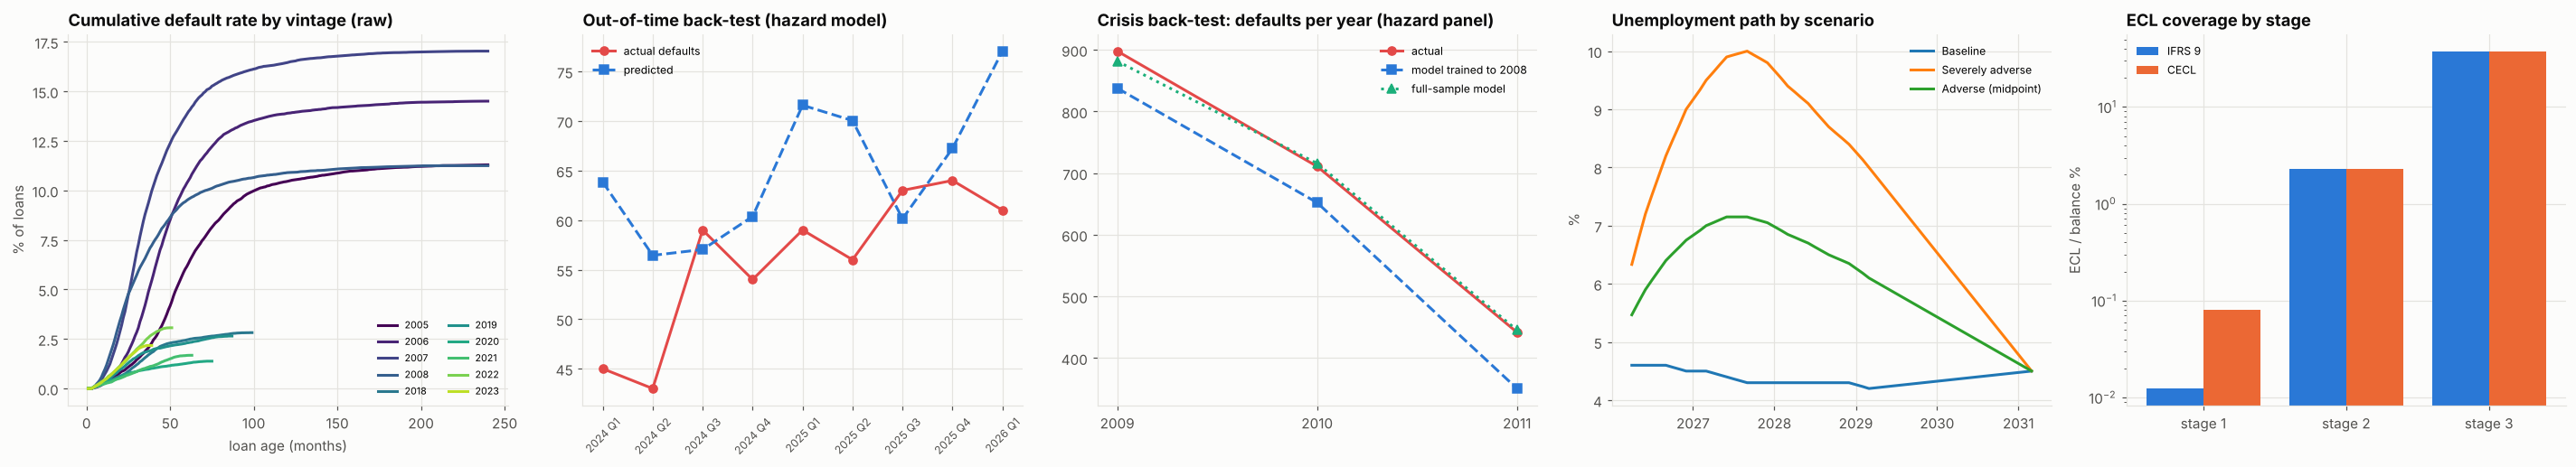

In [12]:
fig, axes = plt.subplots(1, 5, figsize=(26, 4.8))
ax = axes[0]
for (v, g), col in zip(ev.groupby("vintage"), plt.cm.viridis(
        np.linspace(0, 0.9, ev["vintage"].nunique()))):
    t = np.arange(1, 241)
    surv_default = (
        np.array(
            [((g["event"] == "default") & (g["T"] <= k)).sum() for k in t]
        )
        / len(g)
        * 100
    )
    ax.plot(
        t[: int(g["T"].max())],
        surv_default[: int(g["T"].max())],
        color=col,
        label=str(v),
    )
ax.set_title("Cumulative default rate by vintage (raw)")
ax.set_xlabel("loan age (months)")
ax.set_ylabel("% of loans")
ax.legend(fontsize=7, ncol=2)
ax = axes[1]
ax.plot(
    bt.index,
    bt["actual defaults"],
    "o-",
    color=PALETTE[7],
    label="actual defaults",
)
ax.plot(
    bt.index,
    bt["predicted defaults"],
    "s--",
    color=PALETTE[0],
    label="predicted",
)
ax.set_title("Out-of-time back-test (hazard model)")
ax.tick_params(axis="x", rotation=45, labelsize=8)
ax.legend(fontsize=8)
ax = axes[2]
ax.plot(cbt.index, cbt["actual"], "o-", color=PALETTE[7], label="actual")
ax.plot(cbt.index, cbt["pre_crisis"], "s--", color=PALETTE[0],
        label="model trained to 2008")
ax.plot(cbt.index, cbt["full_sample"], "^:", color=PALETTE[2],
        label="full-sample model")
ax.set_title("Crisis back-test: defaults per year (hazard panel)")
ax.set_xticks(cbt.index)
ax.legend(fontsize=8)
ax = axes[3]
for s_, pth in paths.items():
    ax.plot(pth.index[:60], pth["unrate"].iloc[:60], label=s_)
ax.set_title("Unemployment path by scenario")
ax.set_ylabel("%")
ax.legend(fontsize=8)
ax = axes[4]
x = np.arange(3)
ax.bar(
    x - 0.2,
    by_stage.reindex([1, 2, 3])["IFRS 9 coverage %"],
    0.4,
    color=PALETTE[0],
    label="IFRS 9",
)
ax.bar(
    x + 0.2,
    by_stage.reindex([1, 2, 3])["CECL coverage %"],
    0.4,
    color=PALETTE[1],
    label="CECL",
)
ax.set_xticks(x, ["stage 1", "stage 2", "stage 3"])
ax.set_yscale("log")
ax.set_ylabel("ECL / balance %")
ax.set_title("ECL coverage by stage")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_vintages_backtest_scenarios_ecl")
plt.show()

## 9. Reading the results and limitations

500,000 loans, observed to March 2026: 200,000 Fannie Mae loans from 2005–08 and 300,000 Freddie Mac loans from 2018–23; 170,190 still active with \$41.4bn of balance.

**Two worlds.** The crisis vintages defaulted at 11–17% (2007 is the worst at 17%), against 1.4–3.1% for 2018–23, and their foreclosure and short sales lost a median 44% of the balance. The recent vintages' few credit events sold for *more* than the balance (median severity −10%) after a 50% rise in house prices. Both groups mostly prepaid: 81–87% of the crisis loans and 79% of the 2018 vintage, against 19% of the 2021 vintage locked in at 3%.

**DeepSurv ranks risk best, by a little.** On origination data DeepSurv reaches a test C-index of **0.821**, Cox 0.809 and the random survival forest 0.804. Per standard deviation, Cox's hazard ratios are 0.61 for credit score, 1.55 for the note rate, 1.32 for combined LTV, 1.23 for DTI and 1.22 for a single borrower; later vintages are safer (0.78), which is the crisis seen from origination data.

**With the crisis in the data, equity matters.** In the monthly default hazard the mark-to-market LTV now carries real weight (+0.24 log-odds per 15 points, z = 13; it was insignificant on the 2018–23 loans alone), and house-price growth six months earlier enters with −0.038 per point, the same as the aggregate satellite (−0.036). Unemployment adds little once house prices and LTV are in the model (+0.024 per point, z = 1.7, against +0.19 in the satellite): in loan data the crisis worked through negative equity. Last month's delinquency remains the strongest signal (+3.7 after 30 days, +9.6 after 60). In the Fed's severely adverse scenario (unemployment 10%, house prices −16%) the default hazard peaks at **2.2 times** its training average.

**Two back-tests.** Out of time (2024 Q1 – 2026 Q1) the default model ranks loan-months with an AUC of 0.96 and predicts 584 defaults against 504 (+16%); prepayment is now close (4,676 against 4,973) because the crisis years add a period of weak refinancing. The harder test: a model trained only on data to December 2008 predicts 2009–2011 defaults 7%, 8% and 21% too low. It ranks loans almost perfectly (AUC 0.997, mostly through delinquency) but cannot know how long the crisis would last.

**LGD is where the crisis changes the answer most.** The 13,507 crisis disposals lost 45% on average, and the loss barely depends on the rebuilt LTV: 35% below 60% LTV, 45–49% above it. Foreclosure costs, unpaid interest and the discount on a distressed sale take a large share even when the borrower had equity. The structural formula with a 25% haircut predicts 0% below 60% LTV and 53% above 120%; it gets the average right only for underwater loans.

**Staging and ECL.** 168,262 loans are stage 1 (\$40.9bn), 1,823 stage 2 (\$0.43bn) and 105 stage 3 (\$32mm). With the crisis LGD, probability-weighted ECL is **\$27.1mm under IFRS 9** and **\$54.6mm under CECL**, double because stage 1 carries lifetime ECL under CECL. Coverage is 1.2 bp (IFRS 9) and 8 bp (CECL) in stage 1, 2.3% in stage 2 and 38% in stage 3. CECL ECL is \$52.3mm in the baseline, \$56.5mm adverse and \$63.1mm severely adverse: PD moves with the scenarios, LGD hardly does. With the structural LGD instead, CECL ECL would be **\$9.0mm**, a sixth: on a book with 57% average LTV, the LGD assumption moves the reserve more than any scenario.

**Where the reserve sits.** The 2022–23 vintages carry 14–15 bp of CECL coverage against 10–13 bp for 2018–21; the surviving 2005–08 loans, small and well seasoned, carry 4–8 bp.

**Limitations**

- The Fannie Mae loans have no published estimated LTV; it is rebuilt with state house-price indices, which miss neighbourhood-level price falls and probably explain part of the flat LGD curve.
- The two samples come from different agencies and periods; vintage and era are not separable from macro conditions, and the crisis loans are only the ones Fannie Mae acquired (no subprime).
- After the first projected month, surviving loans are assumed current; a roll-rate model would project delinquency explicitly.
- The ECL is before the GSE guarantee and any credit-risk transfer, and excludes qualitative overlays an auditor would expect.

In [13]:
surv_cmp.to_csv(OUT_DIR / "survival_model_comparison.csv")
hr.to_csv(OUT_DIR / "cox_hazard_ratios.csv")
coefs.to_csv(OUT_DIR / "hazard_model_coefficients.csv")
bt.to_csv(OUT_DIR / "out_of_time_backtest.csv")
cbt.to_csv(OUT_DIR / "crisis_backtest_2009_2011.csv")
LGD_FIT.to_csv(OUT_DIR / "lgd_calibration_crisis.csv")
by_stage.to_csv(OUT_DIR / "ecl_by_stage.csv")
by_scen.to_csv(OUT_DIR / "ecl_by_scenario.csv")
vint_tab.to_csv(OUT_DIR / "lifetime_pd_by_vintage.csv")
print(
    "Outputs written:", ", ".join(sorted(p_.name for p_ in OUT_DIR.iterdir()))
)

Outputs written: 01_vintages_backtest_scenarios_ecl.png, cox_hazard_ratios.csv, crisis_backtest_2009_2011.csv, ecl_by_scenario.csv, ecl_by_stage.csv, hazard_model_coefficients.csv, lgd_calibration_crisis.csv, lifetime_pd_by_vintage.csv, out_of_time_backtest.csv, survival_model_comparison.csv


## References

### Finance and regulation

- International Accounting Standards Board. (2014). *IFRS 9 Financial instruments*. IFRS Foundation. https://www.ifrs.org/issued-standards/list-of-standards/ifrs-9-financial-instruments/
- Deng, Y., Quigley, J. M., & Van Order, R. (2000). Mortgage terminations, heterogeneity and the exercise of mortgage options. *Econometrica, 68*(2), 275–307. https://doi.org/10.1111/1468-0262.00110
- Bellotti, T., & Crook, J. (2009). Credit scoring with macroeconomic variables using survival analysis. *Journal of the Operational Research Society, 60*(12), 1699–1707. https://doi.org/10.1057/jors.2008.130
- Fine, J. P., & Gray, R. J. (1999). A proportional hazards model for the subdistribution of a competing risk. *Journal of the American Statistical Association, 94*(446), 496–509. https://doi.org/10.1080/01621459.1999.10474144
- Fannie Mae. (2026). *Single-Family Loan Performance Data* [Data set]. https://capitalmarkets.fanniemae.com/credit-risk-transfer/single-family-credit-risk-transfer/fannie-mae-single-family-loan-performance-data

### Machine learning and deep learning

- Katzman, J. L., Shaham, U., Cloninger, A., Bates, J., Jiang, T., & Kluger, Y. (2018). DeepSurv: Personalized treatment recommender system using a Cox proportional hazards deep neural network. *BMC Medical Research Methodology, 18*, 24. https://doi.org/10.1186/s12874-018-0482-1
- Ishwaran, H., Kogalur, U. B., Blackstone, E. H., & Lauer, M. S. (2008). Random survival forests. *The Annals of Applied Statistics, 2*(3), 841–860. https://doi.org/10.1214/08-AOAS169
- Cox, D. R. (1972). Regression models and life-tables. *Journal of the Royal Statistical Society: Series B, 34*(2), 187–202. https://doi.org/10.1111/j.2517-6161.1972.tb00899.x
- Davidson-Pilon, C. (2019). lifelines: Survival analysis in Python. *Journal of Open Source Software, 4*(40), 1317. https://doi.org/10.21105/joss.01317